# Imports e Bibliotecas

In [194]:
import pandas as pd
import numpy as np
from enum import Enum
from math import floor as floor
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Dataset

In [196]:
deep_seek_v3_coleta = pd.read_csv("/content/Corpus_DeepSeek-V3.csv")
gpt_2_coleta = pd.read_csv("/content/Corpus_gpt-2.csv")
grok_1_coleta = pd.read_csv("/content/Corpus_grok-1.csv")
llama_coleta = pd.read_csv("/content/Corpus_llama.csv")
llama3_coleta = pd.read_csv("/content/Corpus_llama3.csv")

In [197]:
deep_seek_v3_coleta['Repositorio'] = 'DeepSeek_V3'
gpt_2_coleta['Repositorio'] = 'GPT_2'
grok_1_coleta['Repositorio'] = 'Grok_1'
llama_coleta['Repositorio'] = 'Llama'
llama3_coleta['Repositorio'] = 'Llama3'

In [198]:
todos = pd.concat([deep_seek_v3_coleta, gpt_2_coleta, grok_1_coleta, llama_coleta, llama3_coleta], ignore_index=True)

## Adicionando coluna $Validadas$
Representa se a *issue* está nos conjuntos das *issues* validadas como relacionadas à ética ou não

In [199]:
id_issues_validadas = pd.read_csv("/content/validadas.csv")

In [200]:
def addColunaValidada(dataset, id_issues_validadas):
  dataset['Validada'] = dataset['IdIssue'].isin(id_issues_validadas['IdIssue'])
  return dataset

In [201]:
todos = addColunaValidada(todos,id_issues_validadas)

## Identificando quem contribuiu para discussão

In [202]:
contribuintes = pd.read_csv('/content/ValidacaoExtra.csv')

In [203]:
contribuintes['Soma_Total'] = contribuintes['QtdComentarios'] + contribuintes['Info']
soma_agrupada = contribuintes.groupby(['IdIssue', 'Autor'])['Soma_Total'].sum().reset_index()
todos = todos.merge(
    soma_agrupada,
    left_on=['IdIssue', 'AutorComentario'],
    right_on=['IdIssue', 'Autor'],
    how='left'
)
todos.rename(columns={'Soma_Total': 'Volume'}, inplace=True)
todos['Volume'] = todos['Volume'].fillna(0)
todos.drop(columns=['Autor'], inplace=True)

## Anonimização

In [204]:
def anonimizaAutores(dataset):
  cp = dataset.copy()
  cp['AutorComentario'] = pd.factorize(cp['AutorComentario'])[0]
  cp['IdIssue'] = pd.factorize(cp['IdIssue'])[0]
  cp = cp.drop(columns=['LinkIssue','NumeroComentario','Comentario','Info'])
  return cp

### Split Dataset
1. Dataset somente com *issues* validadas como relacionadas à ética
3. Dataset somente com *issues* invalidadas como relacionadas à ética
---
> Permite avaliar se existe transversalidade fora do contexto de investigação de aspectos éticos

> Quero avaliar também a visão geral, ou seja, se um usuário que participou de uma discussão que cobria aspectos éticos também abordou outros temas não relacionados a aspectos éticos ao longo dos repositórios

In [205]:
todos_anon=anonimizaAutores(todos)
todos_validadas=todos_anon[todos_anon['Validada']]
todos_invalidadas=todos_anon[todos_anon['Validada']==False]

In [206]:
todos_anon.head(10) #as colunas: Termos_Info, Termos_Comentario e Termos poderiam ser descartadas também, uma vez que não foram usadas

,IdIssue,AutorComentario,Termos_Info,Termos_Comentario,Termos,Repositorio,Validada,Volume
0,0,0,,,,DeepSeek_V3,False,0.0
1,1,1,,,,DeepSeek_V3,False,0.0
2,2,2,,,,DeepSeek_V3,True,1.0
3,2,3,,,,DeepSeek_V3,True,0.0
4,2,2,,"ethics, safety","ethics, safety",DeepSeek_V3,True,1.0
5,2,4,,,,DeepSeek_V3,True,0.0
6,2,5,,,,DeepSeek_V3,True,0.0
7,2,2,,,,DeepSeek_V3,True,1.0
8,2,6,,,,DeepSeek_V3,True,0.0
9,2,6,,,,DeepSeek_V3,True,0.0


# Estrutura de Dados

Uma dificuldade deste trabalho foi definir a modelagem das entidades. A estrutura de grafo parecia clara, mas como representar repositório, issue e usuário em 2 entidades (nó/aresta) foi um pouco complexo. Primeiramente, a relação entre elementos, todo repositório possui nenhuma ou várias issues (neste cenário, tem pelo menos várias issues), toda issue pertence a um repositório e pode ter um ou mais participantes, um usuário pode participar de 1 ou várias issues em um ou vários repositórios. Dependendo da modelagem poderia criar uma dependência circular, por exemplo, se uma issue tem vários participantes e um participante tem uma lista de issues.

O que pensei, como o objetivo é analisar a participação de um usuários em diferentes repositórios, preferi dar um foco maior nele, sendo assim ele iria deter as informações para modelagem e análise deste projeto, em suma, o usuário terá uma lista de issues nas quais este participa e cada issue terá a informação do repositório ao qual ela pertence (afinal uma issue pertence a um e somente um repositório)

## Separação de IDs

Separo os ids das validadas/invalidadas como relacionadas à ética para uso futuro

In [207]:
ids_validados = set(todos_validadas['IdIssue'].tolist())

In [208]:
ids_invalidados = set(todos_invalidadas['IdIssue'].tolist())

## Enum Repositórios

Padroniza e facilita a referenciação a um repositório nas EDs

In [209]:
class Repositorios(Enum):
  DeepSeek_V3 = 1
  Grok_1 = 2
  GPT_2 = 3
  Llama = 4
  Llama3 = 5

## Issue

Entidade auxiliar que irá compor um atributo da entidade *Nó Usuário*

> Carrega o id da issue, o repositório ao qual pertence e se nela existe uma discussão que aborda aspecto ético

In [211]:
class Issue:
  def __init__(self, id_issue:int, repositorio:Repositorios):
    self.id_issue = id_issue
    self.repositorio = repositorio
    self.relacionada_etica = self.verificaValidada()

  def verificaValidada(self):
    if self.id_issue in ids_validados:
      return True
    else:
      return False

## Heap

Durante a construção das arestas, percebi o quão caro seria ligar os nós usando somente listas. Um nó se liga a outro se 2 usuários estão participando de uma mesma issue, ou seja, a issue é a aresta.

Se eu colocasse uma lista de usuários em Issue só faria uma dependência circular que queria evitar

Voltando, para popular a matriz de adjacência, seria preciso olhar o id da issue de um usuário e buscar na lista de issues de todos os outros usuários esse mesmo id para todas as issues. Mesmo que eu marcasse as issues já pesquisadas, isso ainda seria caro. Considerando todas as issues com um tamanho $x$ e $n$ a quantidade de usuários (nós), buscar por um id de issue linearmente seria demandaria uma quantidade absurda de operações.

Por isso, pensei em usar uma ED auxiliar para reduzir o custo dessa busca, tabela hash poderia ser complicado desenvolver uma função hash decente num tempo ábil. Pensei em árvore auto-balanceável pelo custo da busca no pior caso ser $O(log(n))$ e não seria preciso ordenar a entrada. Mas, um heap além de ser mais simples de implementar neste cenário, não perde em complexidade para a árvore, além de ser usado em algoritmos que atuam sobre grafos como Dijkstra

In [212]:
class Max_Heap:
  def __init__(self):
    self.issues = [None] #variável dummy para usar lista 1-indexada
    self.tam = 0

  #algoritmos adaptados daqueles apresentados nas aulas expositivas
  def pai(self, indice):
    return floor(indice/2)

  def esquerda(self, indice):
    return 2*indice

  def direita(self, indice):
    return 2*indice + 1

  def troca(self, indiceA, indiceB):
    aux = self.issues[indiceA]
    self.issues[indiceA] = self.issues[indiceB]
    self.issues[indiceB] = aux

  def max_heapify(self, indice):
    esq = self.esquerda(indice)
    dir = self.direita(indice)
    maior = indice

    if esq <= self.tam and self.issues[esq].id_issue > self.issues[maior].id_issue:
      maior = esq
    if dir <= self.tam and self.issues[dir].id_issue > self.issues[maior].id_issue:
      maior = dir

    if maior != indice:
      self.troca(indice, maior)
      self.max_heapify(maior)

  def constroi_max_heap(self, issues):
    tamanho_lista = len(issues)
    self.issues = [None]+list(issues)
    self.tam = tamanho_lista
    for i in range(floor(tamanho_lista/2),0,-1):
      self.max_heapify(i)

  def heap_max(self):
    return self.issues[1]

  def extraiMax(self):
    if self.tam < 1:
      return None

    max = self.issues[1]
    self.issues[1] = self.issues[self.tam]
    self.tam-=1
    self.issues.pop()
    if self.tam > 0:
      self.max_heapify(1)
    return max

  def insert(self, chave):
    self.tam += 1
    self.issues.append(chave)

    indice = self.tam
    p = self.pai(indice)

    while indice > 1 and self.issues[p].id_issue < self.issues[indice].id_issue:
        self.troca(indice, p)
        indice = p
        p = self.pai(indice)

## Nó Usuário

Entidade principal, um nó carrega seu id, uma lista de issues das quais este participou, repositório em mais participou (pensei nisso para uma outra análise dependendo dos resultados, poderia ser substituído por um conjunto incluindo todos repositórios da sua lista de issues), o quanto ele contribuiu para uma discussão que envolvia aspectos éticos

In [213]:
class No_Usuario:
  def __init__(self, id_participante:int, issues:list):
    self.id_participante = id_participante
    self.issues = issues
    self.repositorio_predominante = self.predominancia_repos() #indica o repo que um usuário mais participou ->
                                                                #pode ser bom ter uma lista de todos os repos q participou
    self.volume_discussao_aspectos_eticos = self.discussao_aspectos_eticos()

  # cria discionário com nome do repositório e quantas vezes o repositório apareceu na lista
  # de issues do usuario
  # então, retorna o nome do repositório com maior quantidade de ocorrências na lista de issues do usuário
  def predominancia_repos(self):
    contabiliza_repo = {Repositorios(1).name:0,
                        Repositorios(2).name:0,
                        Repositorios(3).name:0,
                        Repositorios(4).name:0,
                        Repositorios(5).name:0}

    for i in self.issues:
      if i.repositorio.name in contabiliza_repo.keys():
        contabiliza_repo[i.repositorio.name]+=1

    maior = 0
    for i in contabiliza_repo.values():
      if maior < i:
        maior = i

    for chave, valor in contabiliza_repo.items():
      if valor == maior:
        chave_maior = chave

    return chave_maior

  def discussao_aspectos_eticos(self):
    #1.verificar se usuario esta em issue validada -> self.issues.id_issue in ids_validadas
    #2.nas issues validadas do usuario, buscar em todas_validadas o id_participante dele em AutorComentario
    #3.agrupar usuarios filtrados por AutorComentario e somar dado na coluna Volume em todas_validadas pelos agrupamentos
    #4.retornar resultado
    #parece IA, mas fui eu qm escreveu!!!

    ids_issues_usuario = [i.id_issue for i in self.issues]

    df_filtrado = todos_validadas[todos_validadas['IdIssue'].isin(ids_issues_usuario)]

    filtro_autor = df_filtrado['AutorComentario'] == self.id_participante
    df_filtrado = df_filtrado[filtro_autor]

    volume_total = int(df_filtrado['Volume'].sum())

    return volume_total


### Colocando dados num formato usável

Dataframe -> Issue e No_Usuario

In [214]:
issues = []
participantes = []

for row in todos_anon.itertuples(index=False):
  try:
      r = Repositorios[row.Repositorio]
  except KeyError:
      r = None
  issue = Issue(row.IdIssue,r)
  issues.append(issue)
  participante = No_Usuario(row.AutorComentario, [issue]) #juntar info de diferentes linhas de autorComentario em um unico nodo
  participantes.append(participante)

Como um mesmo usuário pode estar espalhado em várias issues, ele pode representar mais de um nó, o que não é interessante. Por isso, o método abaixo que encontra esses usuários espalhados e mescla suas informaçõe

In [215]:
def localizaMescla_participante_repetido(participantes):
    participantes_unicos = {}

    for participante in participantes:
        id_part = participante.id_participante

        if id_part not in participantes_unicos: #agrupa issues repetidas
            issues_limpas = []
            ids_vistos = set()

            for issue in participante.issues:
                if issue.id_issue not in ids_vistos:
                    issues_limpas.append(issue)
                    ids_vistos.add(issue.id_issue)

            participante.issues = issues_limpas
            participantes_unicos[id_part] = participante

        else: #se usuario ja foi visto anteriormente, mescla as informações das ocorrências
            p_existente = participantes_unicos[id_part]
            p_existente.volume_discussao_aspectos_eticos += participante.volume_discussao_aspectos_eticos

            ids_issues_existentes = {issue.id_issue for issue in p_existente.issues}

            for nova_issue in participante.issues:
                if nova_issue.id_issue not in ids_issues_existentes:
                    p_existente.issues.append(nova_issue)
                    ids_issues_existentes.add(nova_issue.id_issue)

    return list(participantes_unicos.values())

In [216]:
#execução do método da célula acima + depuração
participantes_tratados = localizaMescla_participante_repetido(participantes)
for i in participantes_tratados:
  print('=====================================================================')
  print(f'Id_Participante={i.id_participante}')
  print(f'Volume={i.volume_discussao_aspectos_eticos}')
  print(f'Issues:')
  print('*********************************************************************')
  for j in i.issues:
    print(f'\tId Issue = {j.id_issue}')
    print(f'\tRepositório = {j.repositorio.name}')
    print(f'\tValidada = {j.relacionada_etica}')

  print('*********************************************************************')
  print('=====================================================================')

Id_Participante=0
Volume=2
Issues:
*********************************************************************
	Id Issue = 0
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 4
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 13
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 14
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 20
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 21
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 22
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 23
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 28
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 31
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 32
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 35
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 39
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 41
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 45
	Repositório = DeepSeek_V3
	Validada = Fal

Abaixo é repetido o mesmo processo, mas as partições do dataset

#### Validadas como relacionada à ética

In [217]:
issues_validadas = []
participantes_validados = []

for row in todos_validadas.itertuples(index=False):
  try:
      r = Repositorios[row.Repositorio]
  except KeyError:
      r = None
  issueValidada = Issue(row.IdIssue,r)
  issues_validadas.append(issue)
  participante = No_Usuario(row.AutorComentario, [issueValidada]) #juntar info de diferentes linhas de autorComentario em um unico nodo
  participantes_validados.append(participante)

In [218]:
participantesValidados_tratados = localizaMescla_participante_repetido(participantes_validados)
for i in participantesValidados_tratados:
  print('=====================================================================')
  print(f'Id_Participante={i.id_participante}')
  print(f'Volume={i.volume_discussao_aspectos_eticos}')
  print(f'Issues:')
  print('*********************************************************************')
  for j in i.issues:
    print(f'\tId Issue = {j.id_issue}')
    print(f'\tRepositório = {j.repositorio.name}')
    print(f'\tValidada = {j.relacionada_etica}')

  print('*********************************************************************')
  print('=====================================================================')

Id_Participante=2
Volume=16
Issues:
*********************************************************************
	Id Issue = 2
	Repositório = DeepSeek_V3
	Validada = True
*********************************************************************
Id_Participante=3
Volume=0
Issues:
*********************************************************************
	Id Issue = 2
	Repositório = DeepSeek_V3
	Validada = True
*********************************************************************
Id_Participante=4
Volume=0
Issues:
*********************************************************************
	Id Issue = 2
	Repositório = DeepSeek_V3
	Validada = True
*********************************************************************
Id_Participante=5
Volume=0
Issues:
*********************************************************************
	Id Issue = 2
	Repositório = DeepSeek_V3
	Validada = True
*********************************************************************
Id_Participante=6
Volume=0
Issues:
********************************

### Invalidadas como relacionada à ética

In [219]:
issuesInvalidadas = []
participantes_invalidados = []

for row in todos_invalidadas.itertuples(index=False):
  try:
      r = Repositorios[row.Repositorio]
  except KeyError:
      r = None
  issue_invalidada = Issue(row.IdIssue,r)
  issuesInvalidadas.append(issue)
  participante = No_Usuario(row.AutorComentario, [issue_invalidada]) #juntar info de diferentes linhas de autorComentario em um unico nodo
  participantes_invalidados.append(participante)

In [220]:
participantesInvalidados_tratados = localizaMescla_participante_repetido(participantes_invalidados)
for i in participantesInvalidados_tratados:
  print('=====================================================================')
  print(f'Id_Participante={i.id_participante}')
  print(f'Volume={i.volume_discussao_aspectos_eticos}')
  print(f'Issues:')
  print('*********************************************************************')
  for j in i.issues:
    print(f'\tId Issue = {j.id_issue}')
    print(f'\tRepositório = {j.repositorio.name}')
    print(f'\tValidada = {j.relacionada_etica}')

  print('*********************************************************************')
  print('=====================================================================')

Id_Participante=0
Volume=0
Issues:
*********************************************************************
	Id Issue = 0
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 4
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 13
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 14
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 20
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 21
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 22
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 23
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 28
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 31
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 32
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 35
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 39
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 41
	Repositório = DeepSeek_V3
	Validada = False
	Id Issue = 45
	Repositório = DeepSeek_V3
	Validada = Fal

## Grafo

ED principal, nela cada usuário representa um nó e a participação de dois usuários numa mesma issue representa a aresta.

Para investigar a transversalidade, adotei 2 algoritmos para métrica de centralidade de intermediação (betweenness centrality), sendo DFS e algoritmo de Brandes. Outras funções auxiliares foram desenvolvidas para facilitar a implementação dos métodos principais (criação de aresta, DFS e brandes)

**Observação**:
===
O algoritmo de Brandes originalmente é usado em grafos **não ponderados** e **direcionados**, o grafo que modelei é **não ponderado** e **não-direcionado** sendo necessária adaptação como sugerido em [Wikipedia - Algoritmo de Brandes](https://en-wikipedia-org.translate.goog/wiki/Brandes%27_algorithm?_x_tr_sl=en&_x_tr_tl=pt&_x_tr_hl=pt&_x_tr_pto=tc)

In [251]:
#matriz de adjacência, nós se conectam pela quantidade de issues em ambos. Se 2 usuarios participaram de 3 issues ao mesmo tempo, eles tem 3 conexoes
class Grafo:
  def __init__(self, lista_nos):
    self.lista_nos = lista_nos
    self.matrizAdjacencia = []
    self.inicializaMatrizAdjacencia()
    self.criar_aresta()

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~ INICIALIZA MATRIZ ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def inicializaMatrizAdjacencia(self):
    n = len(self.lista_nos)
    self.matrizAdjacencia = [[[] for _ in range(n)] for _ in range(n)]
#===============================================================================

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ EXTRAI NO DADO UM ID ~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def extraiNo_dadoId(self, id):
    for i in self.lista_nos:
      if i.id_participante == id:
        return i
    return None
#===============================================================================

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ CRIA ARESTA ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def criar_aresta(self):
    dicionario_issues = {}
    for i in self.lista_nos:
      for j in i.issues:
        dicionario_issues[j.id_issue] = j

    h = Max_Heap()
    h.constroi_max_heap(list(dicionario_issues.values()))

    heaps_usuarios = [] #id usuario + respectivo heap

    for no in self.lista_nos:
      h_usuario = Max_Heap()
      h_usuario.constroi_max_heap(no.issues)
      elemento_usuario = {"id_participante": no.id_participante, "heap": h_usuario}
      heaps_usuarios.append(elemento_usuario)


    while h.tam > 0:
      m_val = h.extraiMax()
      m_id = m_val.id_issue
      nome_repo = m_val.repositorio.name

      usuariosM = []

      for i in range(len(heaps_usuarios)):
          while heaps_usuarios[i]['heap'].tam > 0:
              s = heaps_usuarios[i]['heap'].heap_max()

              if s.id_issue == m_id:
                  heaps_usuarios[i]['heap'].extraiMax()
                  usuariosM.append(i)
              else:
                break

      for i in range(len(usuariosM)):
          for j in range(i + 1, len(usuariosM)):
              u1 = usuariosM[i]
              u2 = usuariosM[j]

              aresta = (m_id, nome_repo)

              self.matrizAdjacencia[u1][u2].append(aresta)
              self.matrizAdjacencia[u2][u1].append(aresta)
#===============================================================================

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~ VIZINHOS DE UM NÓ ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def vizinhos(self, id_participante):
    v = set()

    indice_alvo = -1
    for i, no in enumerate(self.lista_nos):
        if no.id_participante == id_participante:
            indice_alvo = i
            break

    if indice_alvo == -1:
        return v

    for j, arestas in enumerate(self.matrizAdjacencia[indice_alvo]):
      if len(arestas) > 0:
        id_vizinho = self.lista_nos[j].id_participante
        v.add(id_vizinho)
    return v
#===============================================================================

#===============================================================================
#~~~~~~~~~~~~~~~~~~~~~~ VERIFICA REPOS QUE USUARIO PARTICIPOU ~~~~~~~~~~~~~~~~~~
  def verificaReposUsuario(self, usuario):
    #verificar se nas intersecoes do usuario se ocorreu alguma interacao em um repo que nao esteja em repo_visitado
    repo_visitado = set()
    indice_alvo = -1
    for i, no in enumerate(self.lista_nos):
        if no.id_participante == usuario.id_participante:
            indice_alvo = i
            break
    for arestas in self.matrizAdjacencia[indice_alvo]:
      for id, nome in arestas:
        repo_visitado.add(nome)

    return repo_visitado
#===============================================================================

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ DFS ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def dfs(self, no, visitado):
    #pegar as intersecoes e verificar se um usuario participou de mais de um repositorio
    visitado[no.id_participante] = True
    repos = self.verificaReposUsuario(no)
    id_usuarios_transversais = set()
    if len(repos) > 1:
      id_usuarios_transversais.add(no.id_participante)
    for w in self.vizinhos(no.id_participante):
      if not visitado.get(w, False):
        vizinho = self.extraiNo_dadoId(w)
        if vizinho:
            self.dfs(vizinho, visitado)
    if len(id_usuarios_transversais) < 1:
      return "Não houve usuários que participaram de mais de um repositório"
    return id_usuarios_transversais

#===============================================================================

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~ ALGORITMO DE BRANDES ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def brandes(self):
    centralidade_participantes = {}
    for n in self.lista_nos:
      centralidade_participantes[n.id_participante] = 0

    for s in self.lista_nos:
      s_id = s.id_participante
      pilha_s = [] #uma lista acessada pelo último elemento (topo)

      p_v = {}
      for n in self.lista_nos:
        p_v[n.id_participante] = []

      sigma = {}
      for si in self.lista_nos:
        sigma[si.id_participante] = 0
      sigma[s_id] = 1

      dist = {}
      for n in self.lista_nos:
        dist[n.id_participante] = -1
      dist[s_id] = 0

      fila_q = [s_id] #uma lista acessada primeiro elemento (frente)
      while fila_q:
        v = fila_q.pop(0)
        pilha_s.append(v)

        for w in self.vizinhos(v):
          if dist[w] < 0:
            fila_q.append(w)
            dist[w] = dist[v]+1

          if dist[w] == dist[v]+1:
            sigma[w]+=sigma[v]
            p_v[w].append(v)

      delta = {}
      for n in self.lista_nos:
        delta[n.id_participante] = 0

      while pilha_s:
        w = pilha_s.pop()
        for v in p_v[w]:
          delta[v] += (sigma[v] / sigma[w]) * (1 + delta[w])

        if w != s_id:
          centralidade_participantes[w]+=delta[w]

      for i in centralidade_participantes:
        centralidade_participantes[i] = floor(centralidade_participantes[i]/2)

      return centralidade_participantes
#===============================================================================

## Todo dataset

In [252]:
g = Grafo(participantes_tratados)

### Transversalidade via DFS

In [253]:
dicionario_visitados = {}
for no in participantes_tratados:
    dicionario_visitados[no.id_participante] = False

g.dfs(participantes_tratados[0], dicionario_visitados)

'Não houve usuários que participaram de mais de um repositório'

In [254]:
dicionario_visitados = {}
for n in g.lista_nos:
  dicionario_visitados[n.id_participante] = False

total_componentes_conexas = 0
todos_transversais = set()

for no in g.lista_nos:
    if not dicionario_visitados[no.id_participante]:
        total_componentes_conexas += 1
        print(f"Componente Conexas: {total_componentes_conexas} (Iniciando pelo usuário {no.id_participante})...")

        resultado_dfs = g.dfs(no, dicionario_visitados)

        if isinstance(resultado_dfs, set):
            todos_transversais.update(resultado_dfs)

print(f'\n')
if total_componentes_conexas == 1:
    print("A rede é uma grande componente conexa. Existe um caminho entre qualquer par de desenvolvedores")
else:
    print(f'A rede é fragmentada em {total_componentes_conexas} componentes conexas')

print(f"\nTotal de Usuários Transversais: {len(todos_transversais)}")
if len(todos_transversais) > 0:
    print(f"IDs desses usuários: {list(todos_transversais)}")

Componente Conexas: 1 (Iniciando pelo usuário 0)...
Componente Conexas: 2 (Iniciando pelo usuário 14)...
Componente Conexas: 3 (Iniciando pelo usuário 15)...
Componente Conexas: 4 (Iniciando pelo usuário 26)...
Componente Conexas: 5 (Iniciando pelo usuário 27)...
Componente Conexas: 6 (Iniciando pelo usuário 71)...
Componente Conexas: 7 (Iniciando pelo usuário 72)...
Componente Conexas: 8 (Iniciando pelo usuário 73)...
Componente Conexas: 9 (Iniciando pelo usuário 79)...
Componente Conexas: 10 (Iniciando pelo usuário 95)...
Componente Conexas: 11 (Iniciando pelo usuário 97)...
Componente Conexas: 12 (Iniciando pelo usuário 134)...
Componente Conexas: 13 (Iniciando pelo usuário 137)...
Componente Conexas: 14 (Iniciando pelo usuário 143)...
Componente Conexas: 15 (Iniciando pelo usuário 144)...
Componente Conexas: 16 (Iniciando pelo usuário 155)...
Componente Conexas: 17 (Iniciando pelo usuário 157)...
Componente Conexas: 18 (Iniciando pelo usuário 175)...
Componente Conexas: 19 (Inician

### Transversalidade via Algoritmo de Brandes

In [255]:
cb = g.brandes()
for c,v in cb.items():
  if v > 0:
    print(f'Id Usuário {c} / Valor Centralidade: {v}')

Id Usuário 4 / Valor Centralidade: 3
Id Usuário 9 / Valor Centralidade: 3
Id Usuário 20 / Valor Centralidade: 1
Id Usuário 25 / Valor Centralidade: 1
Id Usuário 30 / Valor Centralidade: 3
Id Usuário 38 / Valor Centralidade: 48
Id Usuário 40 / Valor Centralidade: 14
Id Usuário 84 / Valor Centralidade: 27
Id Usuário 100 / Valor Centralidade: 1
Id Usuário 101 / Valor Centralidade: 1
Id Usuário 109 / Valor Centralidade: 4
Id Usuário 142 / Valor Centralidade: 1
Id Usuário 165 / Valor Centralidade: 6
Id Usuário 167 / Valor Centralidade: 8
Id Usuário 182 / Valor Centralidade: 3
Id Usuário 185 / Valor Centralidade: 2
Id Usuário 268 / Valor Centralidade: 1177
Id Usuário 279 / Valor Centralidade: 1
Id Usuário 293 / Valor Centralidade: 1
Id Usuário 330 / Valor Centralidade: 1
Id Usuário 352 / Valor Centralidade: 5
Id Usuário 380 / Valor Centralidade: 1
Id Usuário 403 / Valor Centralidade: 5
Id Usuário 404 / Valor Centralidade: 4
Id Usuário 427 / Valor Centralidade: 1
Id Usuário 434 / Valor Centra

## Dataset Validadas

In [256]:
g_validados = Grafo(participantesValidados_tratados)

### Transversalidade via DFS

In [257]:
dicionario_visitados = {}
for no in participantesValidados_tratados:
    dicionario_visitados[no.id_participante] = False

g_validados.dfs(participantesValidados_tratados[0], dicionario_visitados)

'Não houve usuários que participaram de mais de um repositório'

In [258]:
dicionario_visitados = {}
for n in g_validados.lista_nos:
  dicionario_visitados[n.id_participante] = False

total_componentes_conexas = 0
todos_transversais = set()

for no in g_validados.lista_nos:
    if not dicionario_visitados[no.id_participante]:
        total_componentes_conexas += 1
        print(f"Componente Conexas: {total_componentes_conexas} (Iniciando pelo usuário {no.id_participante})...")

        resultado_dfs = g_validados.dfs(no, dicionario_visitados)

        if isinstance(resultado_dfs, set):
            todos_transversais.update(resultado_dfs)
print(f'\n')
if total_componentes_conexas == 1:
    print("A rede é uma grande componente conexa. Existe um caminho entre qualquer par de desenvolvedores")
else:
    print(f'A rede é fragmentada em {total_componentes_conexas} componentes conexas')

print(f"Total de Usuários Transversais: {len(todos_transversais)}")
if len(todos_transversais) > 0:
    print(f"IDs desses usuários: {list(todos_transversais)}")

Componente Conexas: 1 (Iniciando pelo usuário 2)...
Componente Conexas: 2 (Iniciando pelo usuário 37)...
Componente Conexas: 3 (Iniciando pelo usuário 73)...
Componente Conexas: 4 (Iniciando pelo usuário 184)...
Componente Conexas: 5 (Iniciando pelo usuário 182)...
Componente Conexas: 6 (Iniciando pelo usuário 328)...
Componente Conexas: 7 (Iniciando pelo usuário 368)...
Componente Conexas: 8 (Iniciando pelo usuário 394)...
Componente Conexas: 9 (Iniciando pelo usuário 448)...
Componente Conexas: 10 (Iniciando pelo usuário 550)...
Componente Conexas: 11 (Iniciando pelo usuário 623)...
Componente Conexas: 12 (Iniciando pelo usuário 778)...
Componente Conexas: 13 (Iniciando pelo usuário 779)...
Componente Conexas: 14 (Iniciando pelo usuário 868)...
Componente Conexas: 15 (Iniciando pelo usuário 960)...
Componente Conexas: 16 (Iniciando pelo usuário 926)...
Componente Conexas: 17 (Iniciando pelo usuário 1006)...
Componente Conexas: 18 (Iniciando pelo usuário 1022)...
Componente Conexas: 1

### Transversalidade via Algoritmo de Brandes

In [259]:
cb = g_validados.brandes()
for c,v in cb.items():
  if v > 0:
    print(f'Id Usuário {c} / Valor Centralidade: {v}')

## Dataset Invalidadas

In [260]:
g_invalidados = Grafo(participantesInvalidados_tratados)

### Transversalidade via DFS

In [261]:
dicionario_visitados = {}
for no in participantesInvalidados_tratados:
    dicionario_visitados[no.id_participante] = False

g_invalidados.dfs(participantesInvalidados_tratados[0], dicionario_visitados)

'Não houve usuários que participaram de mais de um repositório'

In [262]:
dicionario_visitados = {}
for n in g_invalidados.lista_nos:
  dicionario_visitados[n.id_participante] = False

total_componentes_conexas = 0
todos_transversais = set()

for no in g_invalidados.lista_nos:
    if not dicionario_visitados[no.id_participante]:
        total_componentes_conexas += 1
        print(f"Componente Conexas: {total_componentes_conexas} (Iniciando pelo usuário {no.id_participante})...")

        resultado_dfs = g_invalidados.dfs(no, dicionario_visitados)

        if isinstance(resultado_dfs, set):
            todos_transversais.update(resultado_dfs)
print(f'\n')
if total_componentes_conexas == 1:
    print("A rede é uma grande componente conexa. Existe um caminho entre qualquer par de desenvolvedores")
else:
    print(f'A rede é fragmentada em {total_componentes_conexas} componentes conexas')

print(f"\nTotal de Usuários Transversais: {len(todos_transversais)}")
if len(todos_transversais) > 0:
    print(f"IDs desses usuários: {list(todos_transversais)}")

Componente Conexas: 1 (Iniciando pelo usuário 0)...
Componente Conexas: 2 (Iniciando pelo usuário 14)...
Componente Conexas: 3 (Iniciando pelo usuário 15)...
Componente Conexas: 4 (Iniciando pelo usuário 26)...
Componente Conexas: 5 (Iniciando pelo usuário 27)...
Componente Conexas: 6 (Iniciando pelo usuário 71)...
Componente Conexas: 7 (Iniciando pelo usuário 72)...
Componente Conexas: 8 (Iniciando pelo usuário 79)...
Componente Conexas: 9 (Iniciando pelo usuário 95)...
Componente Conexas: 10 (Iniciando pelo usuário 97)...
Componente Conexas: 11 (Iniciando pelo usuário 134)...
Componente Conexas: 12 (Iniciando pelo usuário 137)...
Componente Conexas: 13 (Iniciando pelo usuário 143)...
Componente Conexas: 14 (Iniciando pelo usuário 144)...
Componente Conexas: 15 (Iniciando pelo usuário 155)...
Componente Conexas: 16 (Iniciando pelo usuário 157)...
Componente Conexas: 17 (Iniciando pelo usuário 175)...
Componente Conexas: 18 (Iniciando pelo usuário 181)...
Componente Conexas: 19 (Inicia

### Transversalidade via Algoritmo de Brandes

In [263]:
cb = g_invalidados.brandes()
for c,v in cb.items():
  if v > 0:
    print(f'Id Usuário {c} / Valor Centralidade: {v}')

Id Usuário 9 / Valor Centralidade: 3
Id Usuário 20 / Valor Centralidade: 1
Id Usuário 25 / Valor Centralidade: 1
Id Usuário 30 / Valor Centralidade: 3
Id Usuário 84 / Valor Centralidade: 23
Id Usuário 4 / Valor Centralidade: 1
Id Usuário 100 / Valor Centralidade: 1
Id Usuário 101 / Valor Centralidade: 1
Id Usuário 109 / Valor Centralidade: 4
Id Usuário 38 / Valor Centralidade: 20
Id Usuário 165 / Valor Centralidade: 6
Id Usuário 167 / Valor Centralidade: 8
Id Usuário 182 / Valor Centralidade: 2
Id Usuário 185 / Valor Centralidade: 2
Id Usuário 268 / Valor Centralidade: 1133
Id Usuário 279 / Valor Centralidade: 1
Id Usuário 330 / Valor Centralidade: 1
Id Usuário 352 / Valor Centralidade: 5
Id Usuário 380 / Valor Centralidade: 2
Id Usuário 403 / Valor Centralidade: 5
Id Usuário 404 / Valor Centralidade: 4
Id Usuário 434 / Valor Centralidade: 1
Id Usuário 440 / Valor Centralidade: 3
Id Usuário 501 / Valor Centralidade: 6
Id Usuário 516 / Valor Centralidade: 1
Id Usuário 526 / Valor Centra

# Visualização

In [264]:
def plotar_grafo(g):
    G = nx.Graph()

    mapa_cores = {
        'DeepSeek_V3': '#00FFFF',
        'Grok_1': '#9B111E',
        'GPT_2': '#008080',
        'Llama': '#1B357E',
        'Llama3': '#CBC3E3'
    }

    for no in g.lista_nos:
        nome_repo = no.repositorio_predominante

        G.add_node(no.id_participante,
                   repo=nome_repo,
                   volume=no.volume_discussao_aspectos_eticos)

    n = len(g.lista_nos)
    for i in range(n):
        for j in range(i + 1, n):
            arestas = g.matrizAdjacencia[i][j]
            qtd_interacoes = len(arestas)

            if qtd_interacoes > 0:
                u1 = g.lista_nos[i].id_participante
                u2 = g.lista_nos[j].id_participante
                G.add_edge(u1, u2, weight=qtd_interacoes)

    cores_nos = []
    tamanhos_nos = []

    for id_no in G.nodes():
        dados = G.nodes[id_no]

        tamanho_calculado = (dados['volume'] + 1) * 60
        tamanhos_nos.append(tamanho_calculado)

        cor = mapa_cores.get(dados['repo'], 'gray')
        cores_nos.append(cor)

    espessuras_arestas = [G[u][v]['weight'] for u, v in G.edges()]

    plt.figure(figsize=(20, 15))
    #ITERAÇÕES E FORÇA AQUI !!!!!!!!!!!!!!!!!!!!!!!!!!!!!
    pos = nx.spring_layout(G, k=4, iterations=500)

    nx.draw_networkx_nodes(G, pos,
                           node_color=cores_nos,
                           node_size=tamanhos_nos,
                           edgecolors='black',
                           linewidths=1.5)

    nx.draw_networkx_edges(G, pos,
                           edge_color='black',
                           width=espessuras_arestas,
                           alpha=0.7)

    legendas = []
    for nome_repo, cor in mapa_cores.items():
        legendas.append(mpatches.Patch(color=cor, label=nome_repo))

    plt.legend(handles=legendas, title="Repositório Predominante",
               loc='upper right', bbox_to_anchor=(1.15, 1))

    plt.axis('off')
    plt.show()

**Dataset Inteiro**

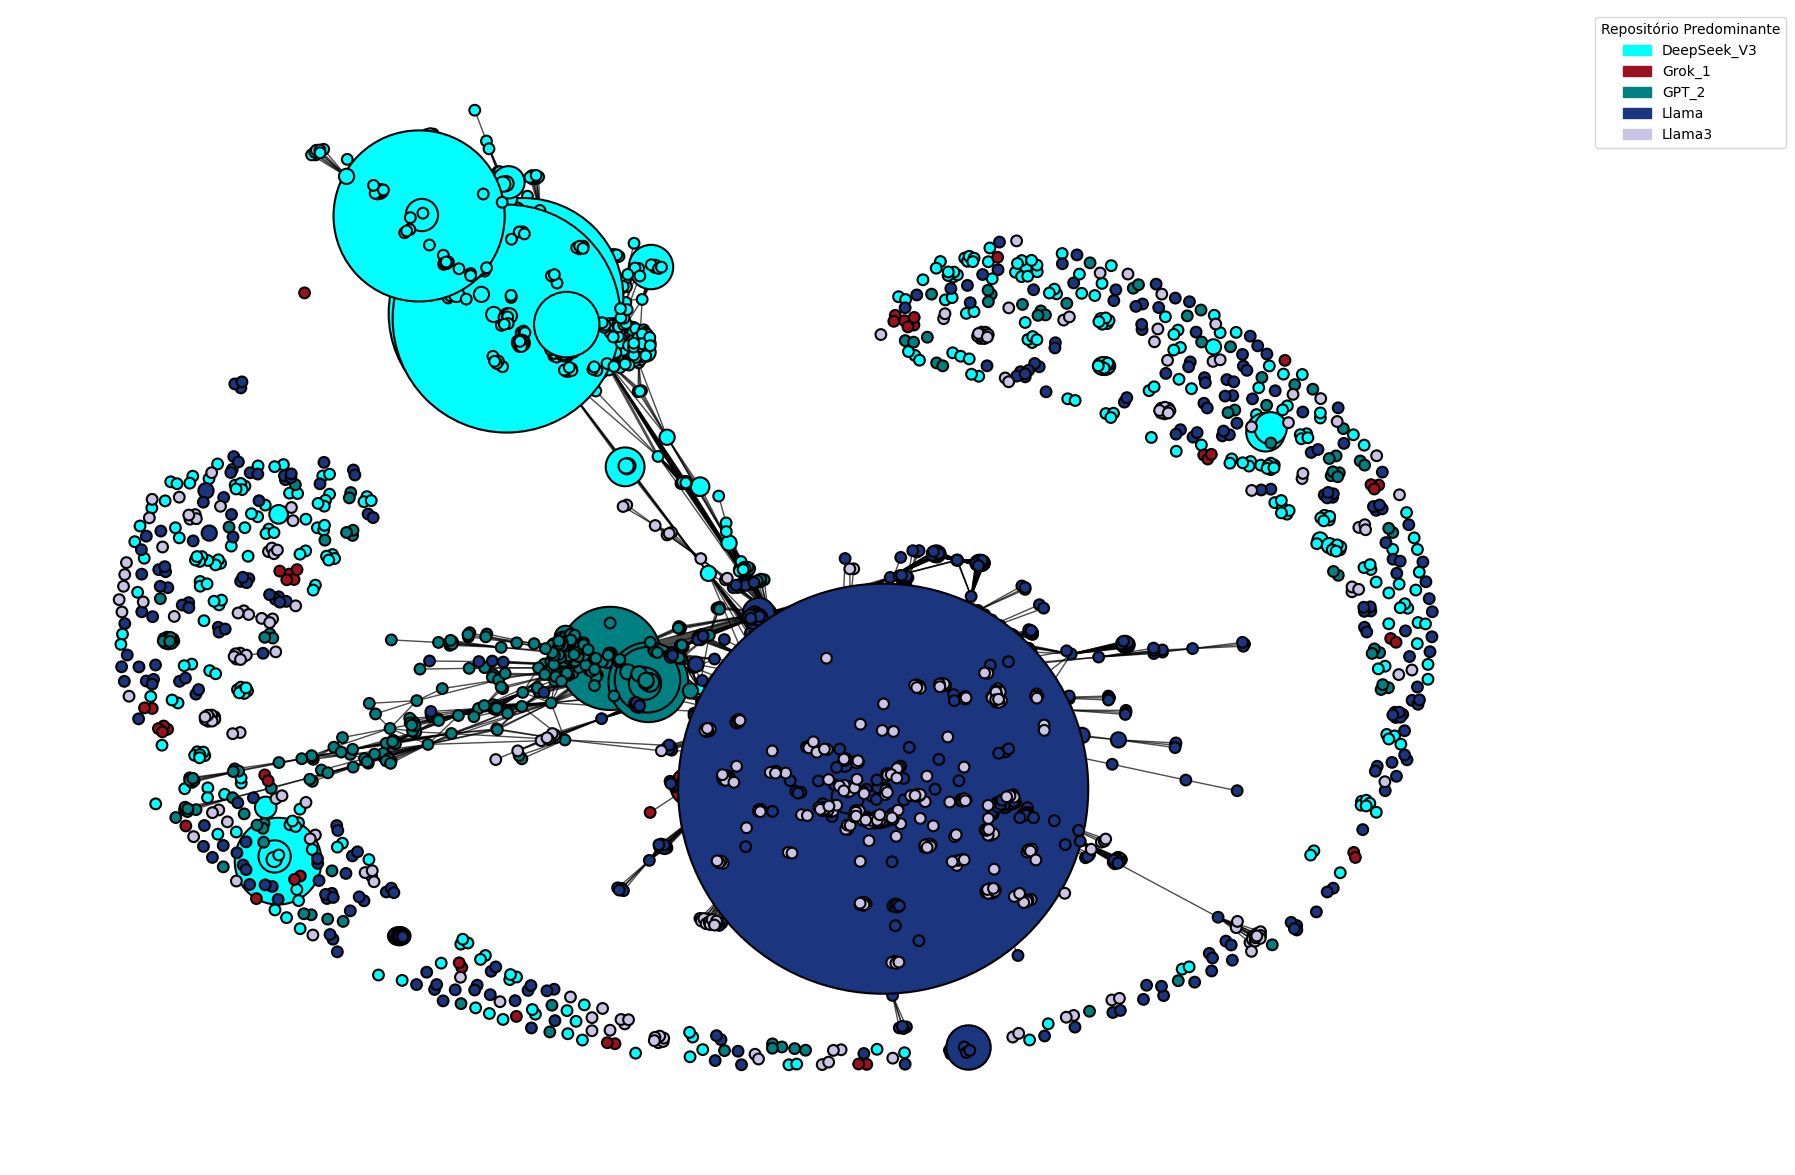

In [265]:
plotar_grafo(g)

**Somente *issues* validadas como relacionadas à ética**

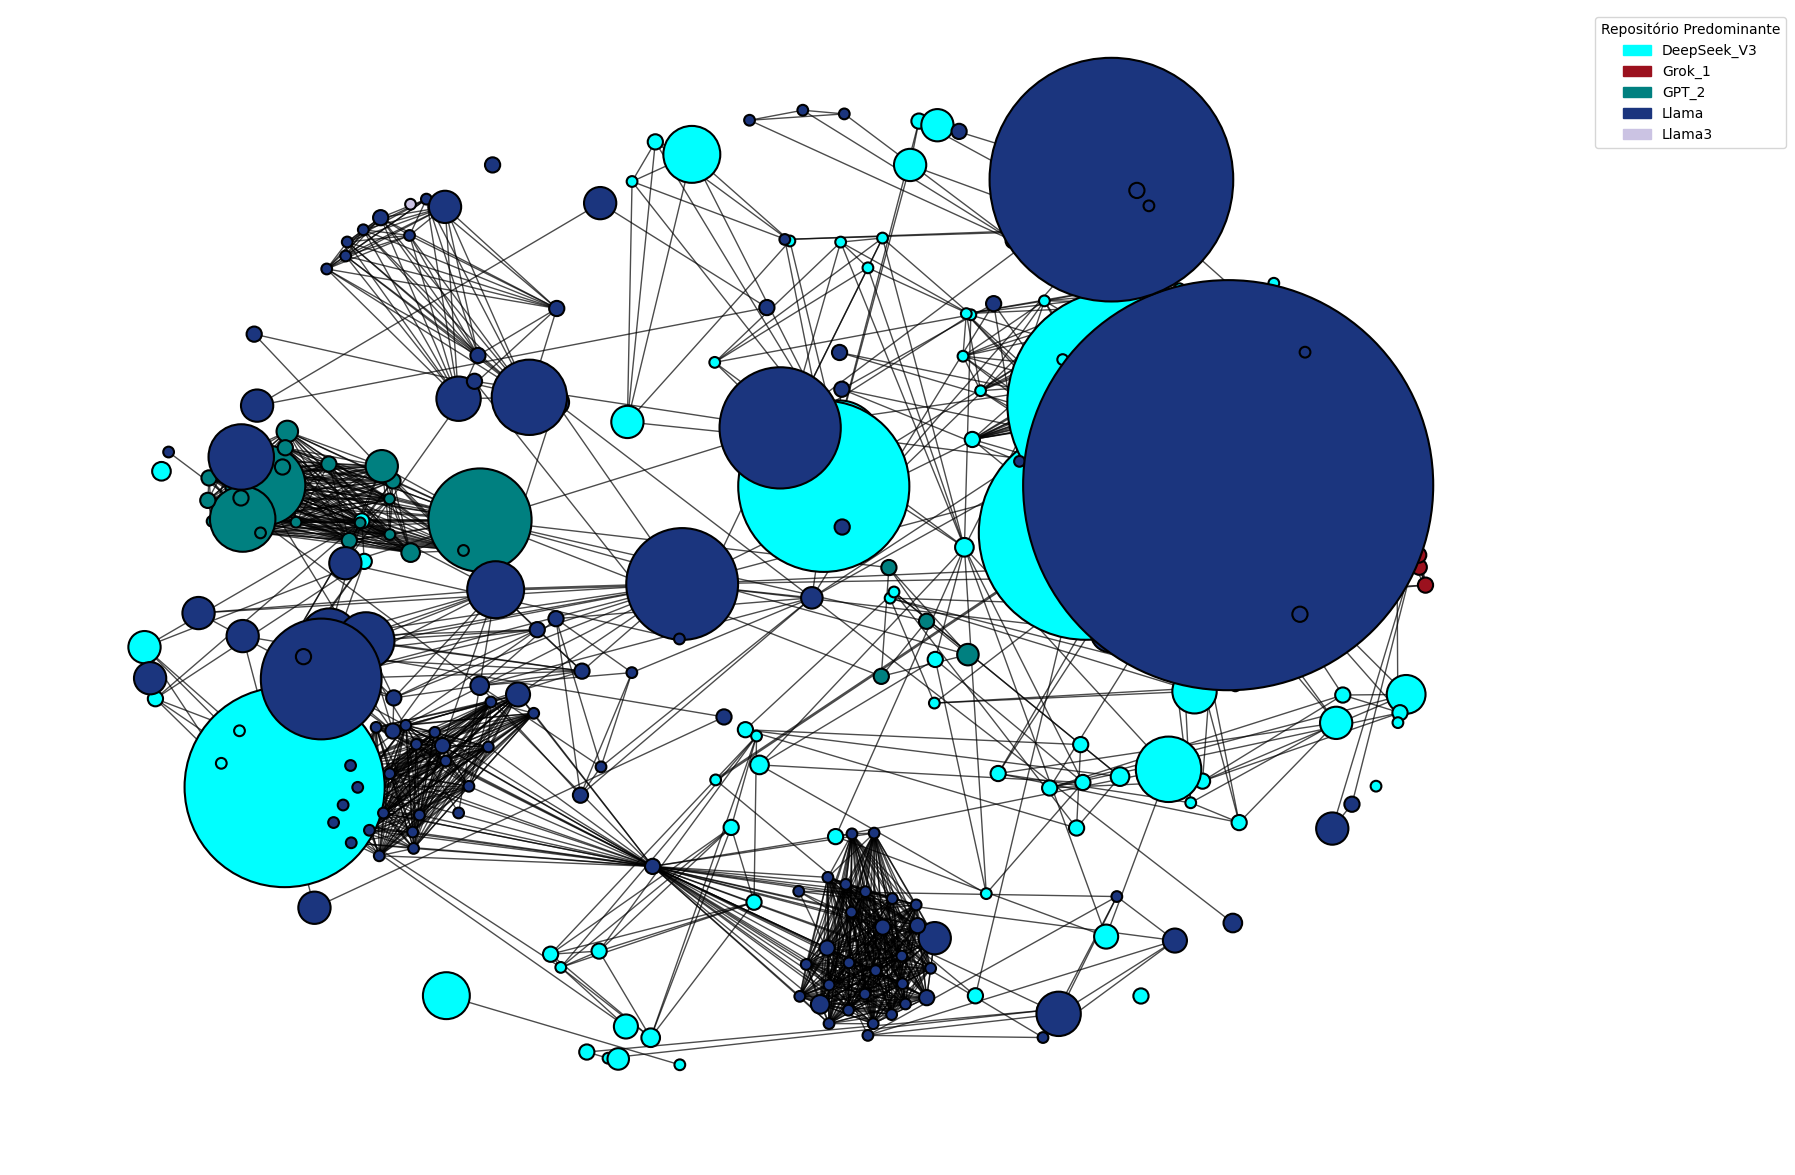

In [266]:
plotar_grafo(g_validados)

**Somente *issues* INVALIDADAS como relacionadas à ética**

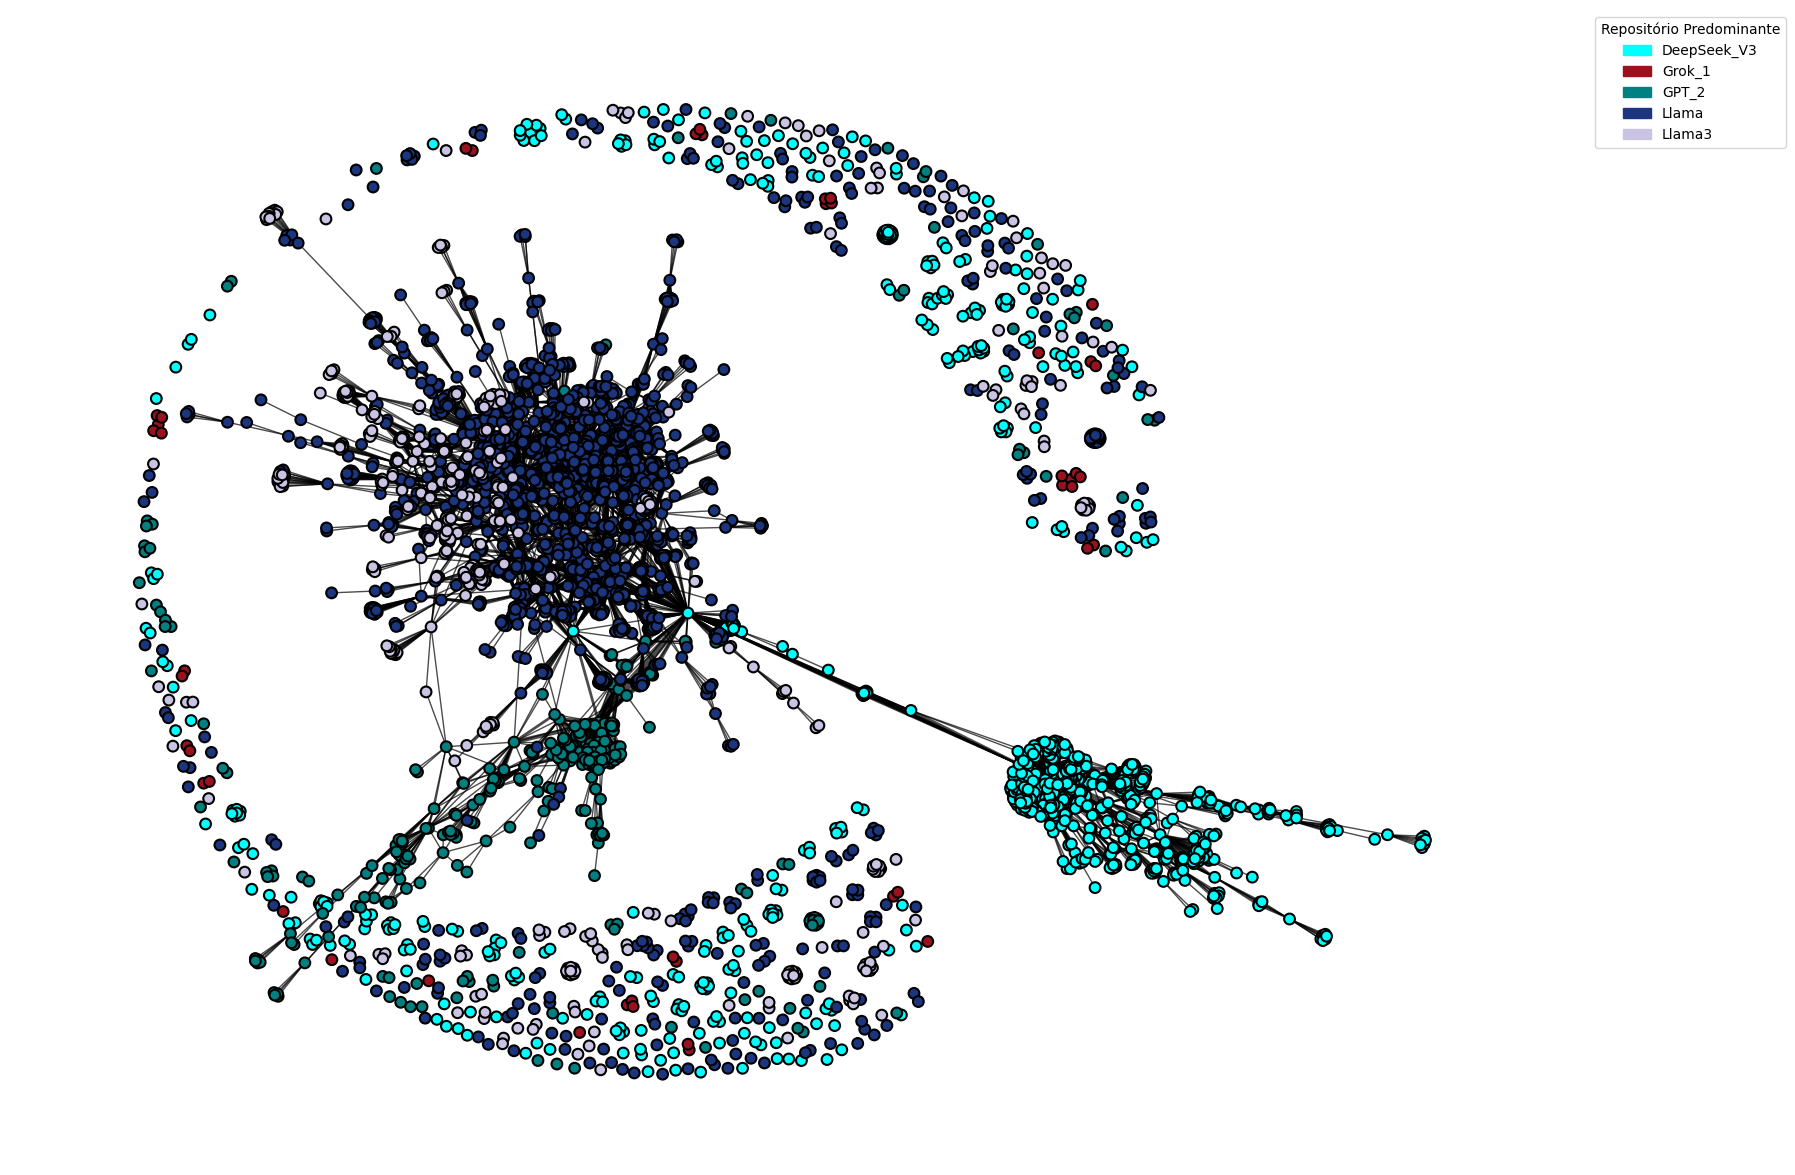

In [267]:
plotar_grafo(g_invalidados)

# Análise Desempenho

## Reimplementando com contagem de operações básicas

In [275]:
#matriz de adjacência, nós se conectam pela quantidade de issues em ambos. Se 2 usuarios participaram de 3 issues ao mesmo tempo, eles tem 3 conexoes
class Grafo:
  def __init__(self, lista_nos):
    self.lista_nos = lista_nos
    self.matrizAdjacencia = []
    self.inicializaMatrizAdjacencia()
    self.criar_aresta()

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~ INICIALIZA MATRIZ ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def inicializaMatrizAdjacencia(self):
    n = len(self.lista_nos)
    self.matrizAdjacencia = [[[] for _ in range(n)] for _ in range(n)]
#===============================================================================

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ EXTRAI NO DADO UM ID ~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def extraiNo_dadoId(self, id):
    for i in self.lista_nos:
      if i.id_participante == id:
        return i
    return None
#===============================================================================

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ CRIA ARESTA ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def criar_aresta(self):
    dicionario_issues = {}
    for i in self.lista_nos:
      for j in i.issues:
        dicionario_issues[j.id_issue] = j

    h = Max_Heap()
    h.constroi_max_heap(list(dicionario_issues.values()))

    heaps_usuarios = [] #id usuario + respectivo heap

    for no in self.lista_nos:
      h_usuario = Max_Heap()
      h_usuario.constroi_max_heap(no.issues)
      elemento_usuario = {"id_participante": no.id_participante, "heap": h_usuario}
      heaps_usuarios.append(elemento_usuario)


    while h.tam > 0:
      m_val = h.extraiMax()
      m_id = m_val.id_issue
      nome_repo = m_val.repositorio.name

      usuariosM = []

      for i in range(len(heaps_usuarios)):
          while heaps_usuarios[i]['heap'].tam > 0:
              s = heaps_usuarios[i]['heap'].heap_max()

              if s.id_issue == m_id:
                  heaps_usuarios[i]['heap'].extraiMax()
                  usuariosM.append(i)
              else:
                break

      for i in range(len(usuariosM)):
          for j in range(i + 1, len(usuariosM)):
              u1 = usuariosM[i]
              u2 = usuariosM[j]

              aresta = (m_id, nome_repo)

              self.matrizAdjacencia[u1][u2].append(aresta)
              self.matrizAdjacencia[u2][u1].append(aresta)
#===============================================================================

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~ VIZINHOS DE UM NÓ ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def vizinhos(self, id_participante):
    v = set()

    indice_alvo = -1
    for i, no in enumerate(self.lista_nos):
        if no.id_participante == id_participante:
            indice_alvo = i
            break

    if indice_alvo == -1:
        return v

    for j, arestas in enumerate(self.matrizAdjacencia[indice_alvo]):
      if len(arestas) > 0:
        id_vizinho = self.lista_nos[j].id_participante
        v.add(id_vizinho)
    return v
#===============================================================================

#===============================================================================
#~~~~~~~~~~~~~~~~~~~~~~ VERIFICA REPOS QUE USUARIO PARTICIPOU ~~~~~~~~~~~~~~~~~~
  def verificaReposUsuario(self, usuario):
    #verificar se nas intersecoes do usuario se ocorreu alguma interacao em um repo que nao esteja em repo_visitado
    repo_visitado = set()
    indice_alvo = -1
    for i, no in enumerate(self.lista_nos):
        if no.id_participante == usuario.id_participante:
            indice_alvo = i
            break
    for arestas in self.matrizAdjacencia[indice_alvo]:
      for id, nome in arestas:
        repo_visitado.add(nome)

    return repo_visitado
#===============================================================================

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ DFS ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def dfs(self, no, visitado, cont_op_basica=0):
    #pegar as intersecoes e verificar se um usuario participou de mais de um repositorio
    visitado[no.id_participante] = True
    repos = self.verificaReposUsuario(no)
    id_usuarios_transversais = set()
    if len(repos) > 1:
      id_usuarios_transversais.add(no.id_participante)
    for w in self.vizinhos(no.id_participante):
      cont_op_basica+=1
      print(f'Quantidade de operações básica corrente: {cont_op_basica}')
      if not visitado.get(w, False):
        vizinho = self.extraiNo_dadoId(w)
        if vizinho:
            cont_op_basica, _ = self.dfs(vizinho, visitado, cont_op_basica)
    if len(id_usuarios_transversais) < 1:
      return cont_op_basica, "Não houve usuários que participaram de mais de um repositório"

    print(f'\nTotal de operações básicas = {cont_op_basica}')
    return cont_op_basica, id_usuarios_transversais

#===============================================================================

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~ ALGORITMO DE BRANDES ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def brandes(self, cont_op_basica=0):
    centralidade_participantes = {}
    for n in self.lista_nos:
      centralidade_participantes[n.id_participante] = 0

    for s in self.lista_nos:
      s_id = s.id_participante
      pilha_s = [] #uma lista acessada pelo último elemento (topo)

      p_v = {}
      for n in self.lista_nos:
        p_v[n.id_participante] = []

      sigma = {}
      for si in self.lista_nos:
        sigma[si.id_participante] = 0
      sigma[s_id] = 1

      dist = {}
      for n in self.lista_nos:
        dist[n.id_participante] = -1
      dist[s_id] = 0

      fila_q = [s_id] #uma lista acessada primeiro elemento (frente)
      while fila_q:
        v = fila_q.pop(0)
        pilha_s.append(v)

        for w in self.vizinhos(v):
          if dist[w] < 0:
            fila_q.append(w)
            dist[w] = dist[v]+1

          if dist[w] == dist[v]+1:
            sigma[w]+=sigma[v]
            p_v[w].append(v)

      delta = {}
      for n in self.lista_nos:
        delta[n.id_participante] = 0

      while pilha_s:
        w = pilha_s.pop()
        for v in p_v[w]:
          delta[v] += (sigma[v] / sigma[w]) * (1 + delta[w])
          cont_op_basica+=1
          print(f'Quantidade de operações básica corrente: {cont_op_basica}')

        if w != s_id:
          centralidade_participantes[w]+=delta[w]

      for i in centralidade_participantes:
        centralidade_participantes[i] = floor(centralidade_participantes[i]/2)

      return cont_op_basica, centralidade_participantes
#===============================================================================

## Dataset Inteiro

In [276]:
g = Grafo(participantes_tratados)

### Transversalidade via DFS

In [277]:
dicionario_visitados = {}
for no in participantes_tratados:
    dicionario_visitados[no.id_participante] = False

c_dfs_inteira, s = g.dfs(participantes_tratados[0], dicionario_visitados)
print(f'Foram realizada {c_dfs_inteira} operações básicas')

A saída de streaming foi truncada nas últimas 5000 linhas.
Quantidade de operações básica corrente: 28542
Quantidade de operações básica corrente: 28543
Quantidade de operações básica corrente: 28544
Quantidade de operações básica corrente: 28545
Quantidade de operações básica corrente: 28546
Quantidade de operações básica corrente: 28547
Quantidade de operações básica corrente: 28548
Quantidade de operações básica corrente: 28549
Quantidade de operações básica corrente: 28550
Quantidade de operações básica corrente: 28551
Quantidade de operações básica corrente: 28552
Quantidade de operações básica corrente: 28553
Quantidade de operações básica corrente: 28554
Quantidade de operações básica corrente: 28555
Quantidade de operações básica corrente: 28556
Quantidade de operações básica corrente: 28557
Quantidade de operações básica corrente: 28558
Quantidade de operações básica corrente: 28559
Quantidade de operações básica corrente: 28560
Quantidade de operações básica corrente: 28561
Q

In [291]:
dicionario_visitados = {}
for n in g.lista_nos:
  dicionario_visitados[n.id_participante] = False

total_componentes_conexas = 0
todos_transversais = set()
ops_basicas = []

for no in g.lista_nos:
    if not dicionario_visitados[no.id_participante]:
        total_componentes_conexas += 1
        print(f"Componente Conexas: {total_componentes_conexas} (Iniciando pelo usuário {no.id_participante})...")

        c_dfs_componente_conexa, resultado_dfs = g.dfs(no, dicionario_visitados)
        ops_basicas.append(c_dfs_componente_conexa)

        if isinstance(resultado_dfs, set):
            todos_transversais.update(resultado_dfs)

print(f'\n')
if total_componentes_conexas == 1:
    print("A rede é uma grande componente conexa. Existe um caminho entre qualquer par de desenvolvedores")
else:
    print(f'A rede é fragmentada em {total_componentes_conexas}')

print(f"\nTotal de Usuários Transversais: {len(todos_transversais)}")
if len(todos_transversais) > 0:
    print(f"IDs desses usuários: {list(todos_transversais)}")

c_dfs_conexa_max = max(ops_basicas)
print(f'Foram realizada {c_dfs_conexa_max} operações básicas')

A saída de streaming foi truncada nas últimas 5000 linhas.
Quantidade de operações básica corrente: 31957
Quantidade de operações básica corrente: 31958
Quantidade de operações básica corrente: 31959
Quantidade de operações básica corrente: 31960
Quantidade de operações básica corrente: 31961
Quantidade de operações básica corrente: 31962
Quantidade de operações básica corrente: 31963
Quantidade de operações básica corrente: 31964
Quantidade de operações básica corrente: 31965
Quantidade de operações básica corrente: 31966
Quantidade de operações básica corrente: 31967
Quantidade de operações básica corrente: 31968
Quantidade de operações básica corrente: 31969
Quantidade de operações básica corrente: 31970
Quantidade de operações básica corrente: 31971
Quantidade de operações básica corrente: 31972
Quantidade de operações básica corrente: 31973
Quantidade de operações básica corrente: 31974
Quantidade de operações básica corrente: 31975
Quantidade de operações básica corrente: 31976
Q

### Transversalidade via Algoritmo de Brandes

In [279]:
brandes_inteira, cb = g.brandes()
print(f'\nForam realizadas {brandes_inteira} operações básicas')

Quantidade de operações básica corrente: 1
Quantidade de operações básica corrente: 2
Quantidade de operações básica corrente: 3
Quantidade de operações básica corrente: 4
Quantidade de operações básica corrente: 5
Quantidade de operações básica corrente: 6
Quantidade de operações básica corrente: 7
Quantidade de operações básica corrente: 8
Quantidade de operações básica corrente: 9
Quantidade de operações básica corrente: 10
Quantidade de operações básica corrente: 11
Quantidade de operações básica corrente: 12
Quantidade de operações básica corrente: 13
Quantidade de operações básica corrente: 14
Quantidade de operações básica corrente: 15
Quantidade de operações básica corrente: 16
Quantidade de operações básica corrente: 17
Quantidade de operações básica corrente: 18
Quantidade de operações básica corrente: 19
Quantidade de operações básica corrente: 20
Quantidade de operações básica corrente: 21
Quantidade de operações básica corrente: 22
Quantidade de operações básica corrente: 

## Dataset Validadas

In [285]:
g_validados = Grafo(participantesValidados_tratados)

### Transversalidade via DFS

In [286]:
dicionario_visitados = {}
for no in participantesValidados_tratados:
    dicionario_visitados[no.id_participante] = False

c_dfs_validada, s = g_validados.dfs(participantesValidados_tratados[0], dicionario_visitados)
print(f'Foram realizada {c_dfs_validada} operações básicas')

Quantidade de operações básica corrente: 1
Quantidade de operações básica corrente: 2
Quantidade de operações básica corrente: 3
Quantidade de operações básica corrente: 4
Quantidade de operações básica corrente: 5
Quantidade de operações básica corrente: 6
Quantidade de operações básica corrente: 7
Quantidade de operações básica corrente: 8
Quantidade de operações básica corrente: 9
Quantidade de operações básica corrente: 10
Quantidade de operações básica corrente: 11
Quantidade de operações básica corrente: 12
Quantidade de operações básica corrente: 13
Quantidade de operações básica corrente: 14
Quantidade de operações básica corrente: 15
Quantidade de operações básica corrente: 16
Quantidade de operações básica corrente: 17
Quantidade de operações básica corrente: 18
Quantidade de operações básica corrente: 19
Quantidade de operações básica corrente: 20
Foram realizada 20 operações básicas


In [289]:
dicionario_visitados = {}
for n in g_validados.lista_nos:
  dicionario_visitados[n.id_participante] = False

total_componentes_conexas = 0
todos_transversais = set()
ops_basicas = []

for no in g_validados.lista_nos:
    if not dicionario_visitados[no.id_participante]:
        total_componentes_conexas += 1
        print(f"Componente Conexas: {total_componentes_conexas} (Iniciando pelo usuário {no.id_participante})...")

        c_dfs_componente_conexa_validada, resultadoValidados_dfs = g_validados.dfs(no, dicionario_visitados)
        ops_basicas.append(c_dfs_componente_conexa_validada)

        if isinstance(resultadoValidados_dfs, set):
            todos_transversais.update(resultadoValidados_dfs)

print(f'\n')
if total_componentes_conexas == 1:
    print("A rede é uma grande componente conexa. Existe um caminho entre qualquer par de desenvolvedores")
else:
    print(f'A rede é fragmentada em {total_componentes_conexas} componentes conexas')

print(f"Total de Usuários Transversais: {len(todos_transversais)}")
if len(todos_transversais) > 0:
    print(f"IDs desses usuários: {list(todos_transversais)}")

c_dfs_conexa_validada_max = max(ops_basicas)
print(f'Foram realizada {c_dfs_conexa_validada_max} operações básicas')

Componente Conexas: 1 (Iniciando pelo usuário 2)...
Quantidade de operações básica corrente: 1
Quantidade de operações básica corrente: 2
Quantidade de operações básica corrente: 3
Quantidade de operações básica corrente: 4
Quantidade de operações básica corrente: 5
Quantidade de operações básica corrente: 6
Quantidade de operações básica corrente: 7
Quantidade de operações básica corrente: 8
Quantidade de operações básica corrente: 9
Quantidade de operações básica corrente: 10
Quantidade de operações básica corrente: 11
Quantidade de operações básica corrente: 12
Quantidade de operações básica corrente: 13
Quantidade de operações básica corrente: 14
Quantidade de operações básica corrente: 15
Quantidade de operações básica corrente: 16
Quantidade de operações básica corrente: 17
Quantidade de operações básica corrente: 18
Quantidade de operações básica corrente: 19
Quantidade de operações básica corrente: 20
Componente Conexas: 2 (Iniciando pelo usuário 37)...
Quantidade de operações 

### Transversalidade via Algoritmo de Brandes

In [295]:
brandes_validada, cb_validada = g_validados.brandes()
print(f'\nForam realizadas {brandes_validada} operações básicas')

Quantidade de operações básica corrente: 1
Quantidade de operações básica corrente: 2
Quantidade de operações básica corrente: 3
Quantidade de operações básica corrente: 4

Foram realizadas 4 operações básicas


## Dataset Invalidadas

In [296]:
g_invalidados = Grafo(participantesInvalidados_tratados)

### Transversalidade via DFS

In [297]:
dicionario_visitados = {}
for no in participantesInvalidados_tratados:
    dicionario_visitados[no.id_participante] = False

c_dfs_invalidada, s = g_invalidados.dfs(participantesInvalidados_tratados[0], dicionario_visitados)
print(f'Foram realizada {c_dfs_invalidada} operações básicas')

A saída de streaming foi truncada nas últimas 5000 linhas.
Quantidade de operações básica corrente: 25568
Quantidade de operações básica corrente: 25569
Quantidade de operações básica corrente: 25570
Quantidade de operações básica corrente: 25571
Quantidade de operações básica corrente: 25572
Quantidade de operações básica corrente: 25573
Quantidade de operações básica corrente: 25574
Quantidade de operações básica corrente: 25575
Quantidade de operações básica corrente: 25576
Quantidade de operações básica corrente: 25577
Quantidade de operações básica corrente: 25578
Quantidade de operações básica corrente: 25579
Quantidade de operações básica corrente: 25580
Quantidade de operações básica corrente: 25581
Quantidade de operações básica corrente: 25582
Quantidade de operações básica corrente: 25583
Quantidade de operações básica corrente: 25584
Quantidade de operações básica corrente: 25585
Quantidade de operações básica corrente: 25586
Quantidade de operações básica corrente: 25587
Q

In [298]:
dicionario_visitados = {}
for n in g_invalidados.lista_nos:
  dicionario_visitados[n.id_participante] = False

total_componentes_conexas = 0
todos_transversais = set()
ops_basicas = []

for no in g_invalidados.lista_nos:
    if not dicionario_visitados[no.id_participante]:
        total_componentes_conexas += 1
        print(f"Componente Conexas: {total_componentes_conexas} (Iniciando pelo usuário {no.id_participante})...")

        c_dfs_componente_conexa_invalidada, resultadoinValidados_dfs = g_invalidados.dfs(no, dicionario_visitados)
        ops_basicas.append(c_dfs_componente_conexa_invalidada)

        if isinstance(resultadoinValidados_dfs, set):
            todos_transversais.update(resultadoinValidados_dfs)

print(f'\n')
if total_componentes_conexas == 1:
    print("A rede é uma grande componente conexa. Existe um caminho entre qualquer par de desenvolvedores")
else:
    print(f'A rede é fragmentada em {total_componentes_conexas} componentes conexas')

print(f"Total de Usuários Transversais: {len(todos_transversais)}")
if len(todos_transversais) > 0:
    print(f"IDs desses usuários: {list(todos_transversais)}")

c_dfs_conexa_invalidada_max = max(ops_basicas)
print(f'Foram realizada {c_dfs_conexa_invalidada_max} operações básicas')

A saída de streaming foi truncada nas últimas 5000 linhas.
Quantidade de operações básica corrente: 28946
Quantidade de operações básica corrente: 28947
Quantidade de operações básica corrente: 28948
Quantidade de operações básica corrente: 28949
Quantidade de operações básica corrente: 28950
Quantidade de operações básica corrente: 28951
Quantidade de operações básica corrente: 28952
Quantidade de operações básica corrente: 28953
Quantidade de operações básica corrente: 28954
Quantidade de operações básica corrente: 28955
Quantidade de operações básica corrente: 28956
Quantidade de operações básica corrente: 28957
Quantidade de operações básica corrente: 28958
Quantidade de operações básica corrente: 28959
Quantidade de operações básica corrente: 28960
Quantidade de operações básica corrente: 28961
Quantidade de operações básica corrente: 28962
Quantidade de operações básica corrente: 28963
Quantidade de operações básica corrente: 28964
Quantidade de operações básica corrente: 28965
Q

### Transversalidade via Algoritmo de Brandes

In [299]:
brandes_invalidada, cb_invalidada = g_invalidados.brandes()
print(f'\nForam realizadas {brandes_invalidada} operações básicas')

Quantidade de operações básica corrente: 1
Quantidade de operações básica corrente: 2
Quantidade de operações básica corrente: 3
Quantidade de operações básica corrente: 4
Quantidade de operações básica corrente: 5
Quantidade de operações básica corrente: 6
Quantidade de operações básica corrente: 7
Quantidade de operações básica corrente: 8
Quantidade de operações básica corrente: 9
Quantidade de operações básica corrente: 10
Quantidade de operações básica corrente: 11
Quantidade de operações básica corrente: 12
Quantidade de operações básica corrente: 13
Quantidade de operações básica corrente: 14
Quantidade de operações básica corrente: 15
Quantidade de operações básica corrente: 16
Quantidade de operações básica corrente: 17
Quantidade de operações básica corrente: 18
Quantidade de operações básica corrente: 19
Quantidade de operações básica corrente: 20
Quantidade de operações básica corrente: 21
Quantidade de operações básica corrente: 22
Quantidade de operações básica corrente: 

# Visualização Comparação de Performance

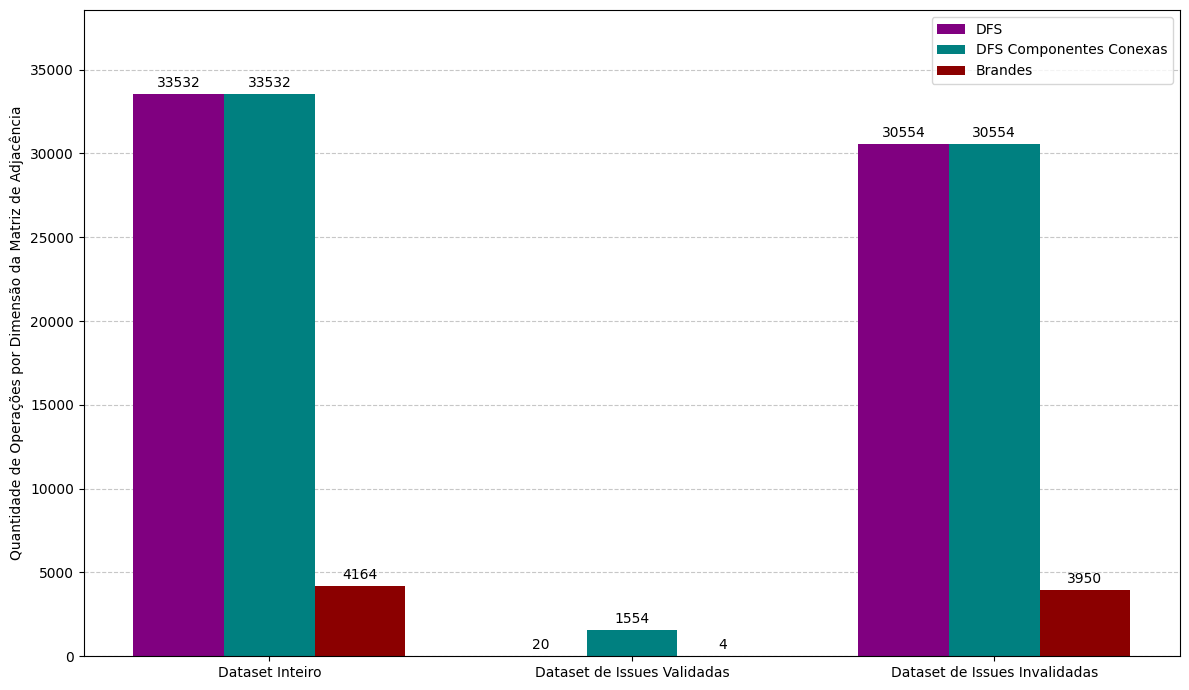

In [319]:
tamanhos = [len(g.lista_nos)**2, len(g_validados.lista_nos)**2, len(g_invalidados.lista_nos)**2]

grupos_x = [
    'Dataset Inteiro',
    'Dataset de Issues Validadas',
    'Dataset de Issues Invalidadas'
]

x_pos = np.arange(len(grupos_x))
largura = 0.25

y_dfs = [c_dfs_inteira, c_dfs_validada, c_dfs_invalidada]
y_dfs_conexa = [c_dfs_conexa_max, c_dfs_conexa_validada_max, c_dfs_conexa_invalidada_max]
y_brandes = [brandes_inteira, brandes_validada, brandes_invalidada]

fig, ax = plt.subplots(figsize=(12, 7))

barras_dfs = ax.bar(x_pos - largura, y_dfs, width=largura, label='DFS', color='purple')
barras_dfs_conexa = ax.bar(x_pos, y_dfs_conexa, width=largura, label='DFS Componentes Conexas', color='teal')
barras_brandes = ax.bar(x_pos + largura, y_brandes, width=largura, label='Brandes', color='darkred')

ax.bar_label(barras_dfs, padding=3)
ax.bar_label(barras_dfs_conexa, padding=3)
ax.bar_label(barras_brandes, padding=3)

ax.set_xticks(x_pos)
ax.set_xticklabels(grupos_x)
ax.set_ylabel('Quantidade de Operações por Dimensão da Matriz de Adjacência')

ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_axisbelow(True)
plt.margins(y=0.15)

plt.tight_layout()
plt.show()